# Lab 5: Predicting Job-Change Intention of Data Scientists with a Neural Network
**Course:** Applied Machine Learning  |  **Student**: Aigerim Alpamyssova BDA-2401

End-to-end pipeline: dataset -> business understanding -> EDA -> cleaning -> feature engineering -> preprocessing -> Keras neural network (+ hyperparameter study) -> evaluation -> conclusion.

In [ ]:
import warnings, random, os, glob, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")

def say(text):
    """Render a Markdown block (used for auto-generated result interpretation)."""
    display(Markdown(text))

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Dataset Selection
**Dataset:** *HR Analytics: Job Change of Data Scientists* (Kaggle, license CC0)
**Link:** https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists

**Context.** A company active in Big Data and Data Science runs training courses and wants to hire data scientists from the people who pass them. It needs to know which enrollees will want to work for the company after training and which will look for a new job elsewhere. The data are candidate profiles collected at enrolment.

- **Target variable:** `target` - 1 = candidate is looking for a job change, 0 = not looking. This is a proxy for *attrition intention*: a candidate who plans to move is likely to leave. -> binary classification.
- **Input features (13):** `city`, `city_development_index`, `gender`, `relevent_experience`, `enrolled_university`, `education_level`, `major_discipline`, `experience`, `company_size`, `company_type`, `last_new_job`, `training_hours` (+ the ID `enrollee_id`).
- Number of observations and features are printed below. The file `aug_train.csv` is used (the Kaggle test file has no labels).

In [ ]:
try:
    import kagglehub
    path = kagglehub.dataset_download("arashnic/hr-analytics-job-change-of-data-scientists")
    csv = [f for f in glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
           if "train" in os.path.basename(f).lower()][0]
    df_raw = pd.read_csv(csv)
except Exception as e:
    print("Automatic download failed:", e, "\nPlease upload aug_train.csv")
    from google.colab import files
    up = files.upload()
    df_raw = pd.read_csv(list(up.keys())[0])

TARGET = "target" if "target" in df_raw.columns else "job_chnge"
if not pd.api.types.is_numeric_dtype(df_raw[TARGET]):
    df_raw[TARGET] = df_raw[TARGET].map({"Yes": 1, "No": 0})
df_raw[TARGET] = df_raw[TARGET].astype(int)

print("Columns:", df_raw.columns.tolist())
display(df_raw.head())
n, p = df_raw.shape
rate = df_raw[TARGET].mean()
say(f"""### Results interpretation- dataset
The dataset has **{n:,} observations** and **{p} columns** ({p-1} feature columns including the ID, plus the target `{TARGET}`).
Class balance: **{rate:.1%}** of candidates are looking for a job change (class 1) and **{1-rate:.1%}** are not (class 0).
The data are therefore **imbalanced** (roughly 1 positive per {(1-rate)/rate:.1f} negatives), so accuracy alone would be misleading — a model that always predicts "not looking" would already score {1-rate:.1%} accuracy.
""")

Using Colab cache for faster access to the 'hr-analytics-job-change-of-data-scientists' dataset.
Columns: ['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours', 'target']


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0


### Results interpretation- dataset
The dataset has **19,158 observations** and **14 columns** (13 feature columns including the ID, plus the target `target`).
Class balance: **24.9%** of candidates are looking for a job change (class 1) and **75.1%** are not (class 0).
The data are therefore **imbalanced** (roughly 1 positive per 3.0 negatives), so accuracy alone would be misleading — a model that always predicts "not looking" would already score 75.1% accuracy.


## 2. Business Understanding
**Real-world problem.** Training a candidate and then losing them to another employer wastes time and money. The company wants to focus recruiting and training investment on candidates who are likely to stay, and to plan retention offers for those who are likely to look elsewhere.

**What the model predicts.** The probability that a candidate is looking for a job change (intention to leave).

**Who uses it.** Talent-acquisition / HR teams and hiring managers. They receive a ranked list of candidates by risk and can prioritise interviews, decide whom to offer a faster onboarding/retention package, and plan headcount more reliably.

**Decision support.** The model never decides automatically - it prioritises human attention. Because the cost of a *missed leaver* (training spent, vacancy reopened) is higher than the cost of one extra conversation, we care mostly about **Recall** of class 1, while keeping **Precision** high enough that HR effort is not wasted.

**Business success criteria** (evaluated on the unseen test set):

| Metric | Target | Why |
|---|---|---|
| ROC-AUC | ≥ 0.75 | ranks risky candidates well, regardless of threshold |
| Recall (class 1) | ≥ 0.60 | catch most candidates who will look elsewhere |
| Precision (class 1) | ≥ 0.40 | well above the base rate (~25%), so alerts are worth acting on |
| F1 (class 1) | ≥ 0.50 | balance of both |
| Train vs test gap | AUC gap < 0.05 | model generalises |

## 3. Exploratory Data Analysis

In [ ]:
df_raw.info()
display(df_raw.describe().T.round(2))
display(df_raw.describe(exclude="number").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  int64  
dtypes: float64(1), int64(3), object(10)
me

,count,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,16875.36,9616.29,1.00,8554.25,16982.5,25169.75,33380.00
city_development_index,19158.0,0.83,0.12,0.45,0.74,0.9,0.92,0.95
training_hours,19158.0,65.37,60.06,1.00,23.00,47.0,88.00,336.00
target,19158.0,0.25,0.43,0.00,0.00,0.0,0.00,1.00


,count,unique,top,freq
city,19158,123,city_103,4355
gender,14650,3,Male,13221
relevent_experience,19158,2,Has relevent experience,13792
enrolled_university,18772,3,no_enrollment,13817
education_level,18698,5,Graduate,11598
major_discipline,16345,6,STEM,14492
experience,19093,22,>20,3286
company_size,13220,8,50-99,3083
company_type,13018,6,Pvt Ltd,9817
last_new_job,18735,6,1,8040


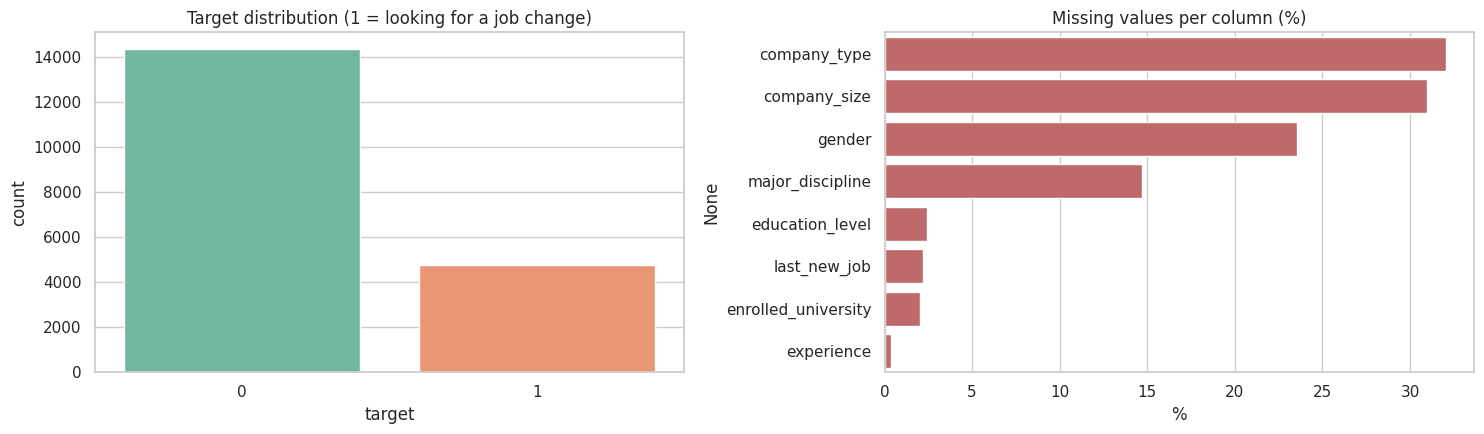

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.countplot(x=TARGET, data=df_raw, ax=ax[0], palette="Set2")
ax[0].set_title("Target distribution (1 = looking for a job change)")
miss_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
miss_pct = miss_pct[miss_pct > 0]
sns.barplot(x=miss_pct.values, y=miss_pct.index, ax=ax[1], color="indianred")
ax[1].set_title("Missing values per column (%)"); ax[1].set_xlabel("%")
plt.tight_layout(); plt.show()

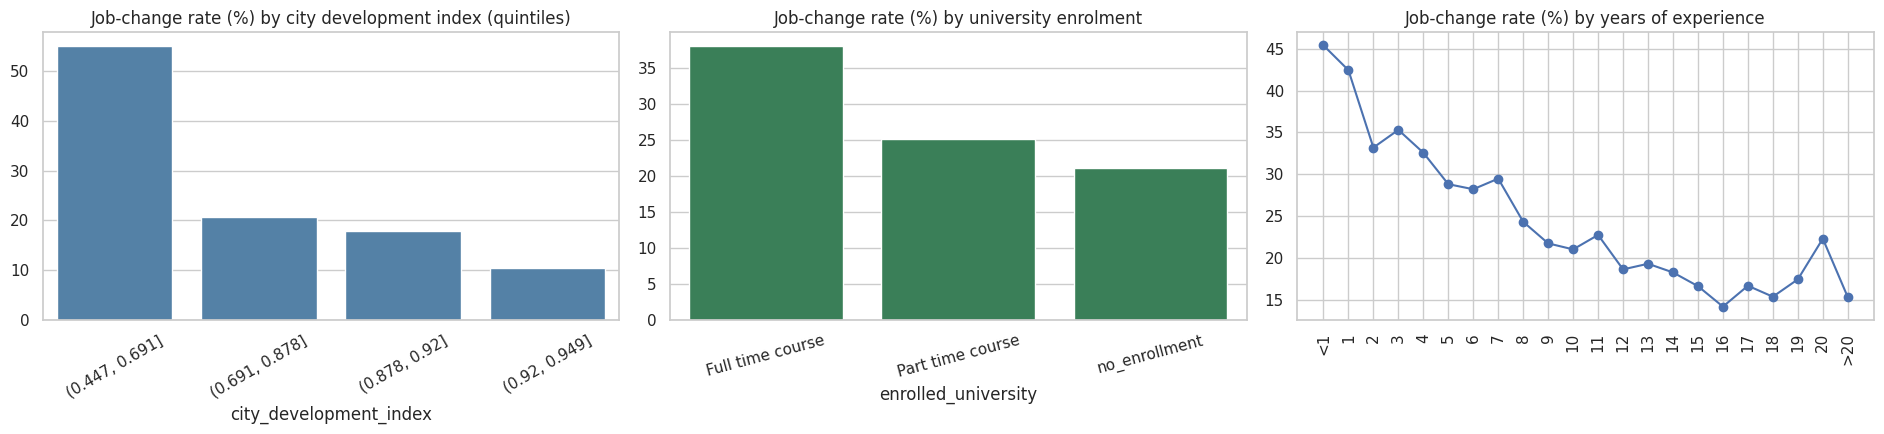

In [ ]:
cdi_q = pd.qcut(df_raw["city_development_index"], 5, duplicates="drop")
r_cdi = df_raw.groupby(cdi_q, observed=True)[TARGET].mean() * 100
r_rel = df_raw.groupby("relevent_experience")[TARGET].mean() * 100
r_uni = df_raw.groupby("enrolled_university")[TARGET].mean() * 100
order = ["<1"] + [str(i) for i in range(1, 21)] + [">20"]
r_exp = (df_raw.groupby("experience")[TARGET].mean() * 100).reindex(order).dropna()

fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
sns.barplot(x=r_cdi.index.astype(str), y=r_cdi.values, ax=ax[0], color="steelblue")
ax[0].set_title("Job-change rate (%) by city development index (quintiles)"); ax[0].tick_params(axis="x", rotation=30)
sns.barplot(x=r_uni.index, y=r_uni.values, ax=ax[1], color="seagreen")
ax[1].set_title("Job-change rate (%) by university enrolment"); ax[1].tick_params(axis="x", rotation=15)
ax[2].plot(r_exp.index, r_exp.values, marker="o"); ax[2].set_title("Job-change rate (%) by years of experience")
ax[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

In [ ]:
miss_ct = df_raw.groupby(df_raw["company_type"].isna())[TARGET].mean() * 100
top_miss = miss_pct.head(3)
say(f"""### Results interpretation - EDA
- **Target:** {df_raw[TARGET].mean():.1%} of candidates look for a change -> imbalanced classes, so we will use Precision/Recall/F1/AUC and tune the decision threshold.
- **Missing data:** the most incomplete columns are {", ".join(f"`{c}` ({v:.1f}%)" for c, v in top_miss.items())}. Missingness is large, so how we treat it matters (see Section 4).
- **City development:** candidates from the least developed cities look for a change in **{r_cdi.iloc[0]:.1f}%** of cases versus **{r_cdi.iloc[-1]:.1f}%** in the most developed ones - {"a big difference, so city_development_index is a strong feature" if abs(r_cdi.iloc[0]-r_cdi.iloc[-1]) > 10 else "a modest difference"}.
- **Relevant experience:** the highest rate is for `{r_rel.idxmax()}` ({r_rel.max():.1f}%) and the lowest for `{r_rel.idxmin()}` ({r_rel.min():.1f}%).
- **University enrolment:** the highest rate is for `{r_uni.idxmax()}` ({r_uni.max():.1f}%), the lowest for `{r_uni.idxmin()}` ({r_uni.min():.1f}%).
- **Experience:** the rate is {r_exp.iloc[:3].mean():.1f}% for the least experienced (first 3 groups) and {r_exp.iloc[-3:].mean():.1f}% for the most experienced (last 3 groups); {"less experienced candidates move more often" if r_exp.iloc[:3].mean() > r_exp.iloc[-3:].mean() else "experienced candidates move more often"}.
- **Missingness is informative:** when `company_type` is missing, the job-change rate is {miss_ct.get(True, float("nan")):.1f}% vs {miss_ct.get(False, float("nan")):.1f}% when it is present - {"so a 'missing' flag can help the model" if abs(miss_ct.get(True, 0)-miss_ct.get(False, 0)) > 5 else "a small difference"}.
""")

### Results interpretation - EDA
- **Target:** 24.9% of candidates look for a change -> imbalanced classes, so we will use Precision/Recall/F1/AUC and tune the decision threshold.
- **Missing data:** the most incomplete columns are `company_type` (32.0%), `company_size` (31.0%), `gender` (23.5%). Missingness is large, so how we treat it matters (see Section 4).
- **City development:** candidates from the least developed cities look for a change in **55.1%** of cases versus **10.4%** in the most developed ones - a big difference, so city_development_index is a strong feature.
- **Relevant experience:** the highest rate is for `No relevent experience` (33.8%) and the lowest for `Has relevent experience` (21.5%).
- **University enrolment:** the highest rate is for `Full time course` (38.1%), the lowest for `no_enrollment` (21.1%).
- **Experience:** the rate is 40.3% for the least experienced (first 3 groups) and 18.3% for the most experienced (last 3 groups); less experienced candidates move more often.
- **Missingness is informative:** when `company_type` is missing, the job-change rate is 38.8% vs 18.4% when it is present - so a 'missing' flag can help the model.


## 4. Data Cleaning

In [ ]:
df = df_raw.copy()
shape_before = df.shape
missing_before = df.isna().sum()
display(pd.DataFrame({"missing": missing_before, "pct": (missing_before / len(df) * 100).round(1)})
        .query("missing > 0").sort_values("missing", ascending=False))

print("Full-row duplicates:", df.duplicated().sum())
print("Duplicate IDs:", df["enrollee_id"].duplicated().sum())
print("Duplicates ignoring ID (same profile + same label):", df.drop(columns="enrollee_id").duplicated().sum())

print("\nCity development index outside [0,1]:", ((df.city_development_index < 0) | (df.city_development_index > 1)).sum())
print("training_hours <= 0:", (df.training_hours <= 0).sum())
print("\nCategory values that need conversion:")
for c in ["experience", "company_size", "last_new_job", "education_level"]:
    print(f"  {c}: {sorted(df[c].dropna().unique().tolist())}")
print("\nData types before:\n", df.dtypes.value_counts())

,missing,pct
company_type,6140,32.0
company_size,5938,31.0
gender,4508,23.5
major_discipline,2813,14.7
education_level,460,2.4
last_new_job,423,2.2
enrolled_university,386,2.0
experience,65,0.3


Full-row duplicates: 0
Duplicate IDs: 0
Duplicates ignoring ID (same profile + same label): 49

City development index outside [0,1]: 0
training_hours <= 0: 0

Category values that need conversion:
  experience: ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '3', '4', '5', '6', '7', '8', '9', '<1', '>20']
  company_size: ['10/49', '100-500', '1000-4999', '10000+', '50-99', '500-999', '5000-9999', '<10']
  last_new_job: ['1', '2', '3', '4', '>4', 'never']
  education_level: ['Graduate', 'High School', 'Masters', 'Phd', 'Primary School']

Data types before:
 object     10
int64       3
float64     1
Name: count, dtype: int64


In [ ]:
#incorrect data types: numeric information stored as text -> ordinal numbers
df["experience_years"] = pd.to_numeric(df["experience"].astype(str).replace({"<1": "0", ">20": "21"}), errors="coerce")
last_map = {"never": 0, "1": 1, "2": 2, "3": 3, "4": 4, ">4": 5}
size_map = {"<10": 0, "10/49": 1, "50-99": 2, "100-500": 3, "500-999": 4, "1000-4999": 5, "5000-9999": 6, "10000+": 7}
edu_map  = {"Primary School": 0, "High School": 1, "Graduate": 2, "Masters": 3, "Phd": 4}
df["last_new_job_years"] = df["last_new_job"].astype(str).map(last_map)
df["company_size_rank"]  = df["company_size"].astype(str).map(size_map)
df["education_rank"]     = df["education_level"].astype(str).map(edu_map)

#safety check: every non-missing original value must have been converted
for orig, new in [("experience", "experience_years"), ("last_new_job", "last_new_job_years"),
                  ("company_size", "company_size_rank"), ("education_level", "education_rank")]:
    unmapped = (df[orig].notna() & df[new].isna()).sum()
    print(f"{orig:16s} -> {new:20s} unmapped values: {unmapped}")

#missing categorical values: 'Unknown' is its own category (missingness is informative)
cat_fill = ["gender", "enrolled_university", "major_discipline", "company_type"]
df[cat_fill] = df[cat_fill].fillna("Unknown")

#drop ID and the original text columns
df = df.drop(columns=["enrollee_id", "experience", "last_new_job", "company_size", "education_level"])

print("\nSHAPE before -> after:", shape_before, "->", df.shape)
print("Missing values before:", int(missing_before.sum()), " -> after categorical fill:", int(df.isna().sum().sum()),
      "(remaining NaN are only in ordinal numeric columns; they are imputed with the TRAIN median inside the pipeline)")
display(df.isna().sum()[df.isna().sum() > 0].to_frame("remaining NaN"))

experience       -> experience_years     unmapped values: 0
last_new_job     -> last_new_job_years   unmapped values: 0
company_size     -> company_size_rank    unmapped values: 0
education_level  -> education_rank       unmapped values: 0

SHAPE before -> after: (19158, 14) -> (19158, 13)
Missing values before: 20733  -> after categorical fill: 6886 (remaining NaN are only in ordinal numeric columns; they are imputed with the TRAIN median inside the pipeline)


,remaining NaN
experience_years,65
last_new_job_years,423
company_size_rank,5938
education_rank,460


training_hours: IQR outliers = 984 (5.1%), skewness = 1.82


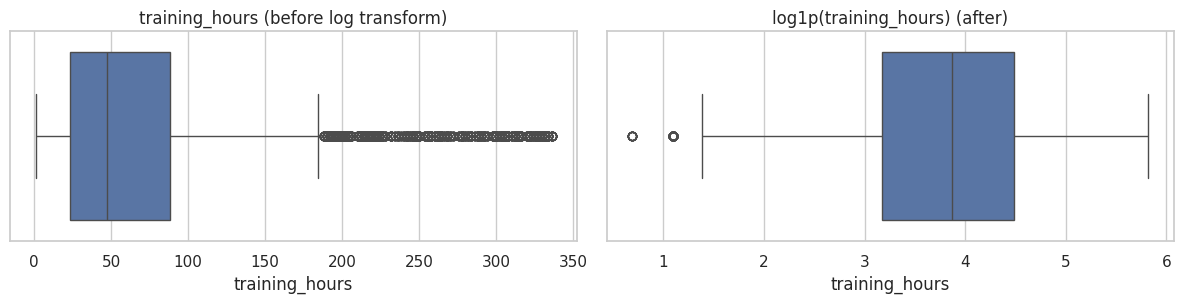

skewness after log1p: -0.35


In [ ]:
#outliers in training_hours (IQR rule)
q1, q3 = df["training_hours"].quantile([.25, .75]); iqr = q3 - q1
n_out = ((df["training_hours"] > q3 + 1.5 * iqr) | (df["training_hours"] < q1 - 1.5 * iqr)).sum()
print(f"training_hours: IQR outliers = {n_out} ({n_out/len(df):.1%}), skewness = {df['training_hours'].skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
sns.boxplot(x=df["training_hours"], ax=ax[0]); ax[0].set_title("training_hours (before log transform)")
sns.boxplot(x=np.log1p(df["training_hours"]), ax=ax[1]); ax[1].set_title("log1p(training_hours) (after)")
plt.tight_layout(); plt.show()
print("skewness after log1p:", round(np.log1p(df["training_hours"]).skew(), 2))

In [ ]:
dup_noid = df.duplicated().sum()
say(f"""### Results interpretation-cleaning
- **Missing values:** {int(missing_before.sum()):,} missing cells were found, mostly in {", ".join(f"`{c}`" for c in missing_before.sort_values(ascending=False).index[:3])}. For categorical columns "Unknown" was created as a separate category because missingness itself carries signal (Section 3). For ordinal numeric columns the median of the **training set** is used later, so no information from the test set leaks.
- **Duplicates:** no duplicated IDs. {dup_noid} rows share an identical profile *and* label; they are kept because they can be different people with the same attributes (all features are coarse categories).
- **Wrong data types:** `experience`, `last_new_job`, `company_size` and `education_level` were stored as text such as "<1", ">20", "10/49" or "Masters". They were converted to ordered numbers (years, size rank, education rank), which a neural network can use directly; the safety check above shows no value was left unmapped.
- **Invalid values:** none (city development index stays within [0, 1], training hours are positive).
- **Outliers:** {n_out} `training_hours` values ({n_out/len(df):.1%}) are IQR outliers, but they are genuine long course durations, so they are **kept**; the log transform reduces skewness from {df["training_hours"].skew():.2f} to {np.log1p(df["training_hours"]).skew():.2f}, which helps gradient descent.
""")

### Results interpretation-cleaning
- **Missing values:** 20,733 missing cells were found, mostly in `company_type`, `company_size`, `gender`. For categorical columns "Unknown" was created as a separate category because missingness itself carries signal (Section 3). For ordinal numeric columns the median of the **training set** is used later, so no information from the test set leaks.
- **Duplicates:** no duplicated IDs. 49 rows share an identical profile *and* label; they are kept because they can be different people with the same attributes (all features are coarse categories).
- **Wrong data types:** `experience`, `last_new_job`, `company_size` and `education_level` were stored as text such as "<1", ">20", "10/49" or "Masters". They were converted to ordered numbers (years, size rank, education rank), which a neural network can use directly; the safety check above shows no value was left unmapped.
- **Invalid values:** none (city development index stays within [0, 1], training hours are positive).
- **Outliers:** 984 `training_hours` values (5.1%) are IQR outliers, but they are genuine long course durations, so they are **kept**; the log transform reduces skewness from 1.82 to -0.35, which helps gradient descent.


## 5. Feature Engineering

In [ ]:
fe = df.copy()
#1)how incomplete the candidate's profile is (informative in this data)
profile_cols = ["gender", "enrolled_university", "major_discipline", "company_size", "company_type",
                "education_level", "last_new_job", "experience"]
fe["missing_info_count"] = df_raw[profile_cols].isna().sum(axis=1).values
#2) training intensity relative to experience (log scale)
fe["log_training_per_exp_year"] = np.log1p(fe["training_hours"] / (fe["experience_years"] + 1))
#3) how recently the candidate changed job relative to total experience (job-hopping proxy)
fe["recent_switch_ratio"] = fe["last_new_job_years"] / (fe["experience_years"] + 1)
#4) log of training hours to reduce skew (replaces the raw column)
fe["log_training_hours"] = np.log1p(fe["training_hours"])
fe = fe.drop(columns=["training_hours"])

new_feats = ["missing_info_count", "log_training_per_exp_year", "recent_switch_ratio", "log_training_hours"]
corr_new = fe[new_feats + [TARGET]].corr()[TARGET].drop(TARGET)
display(fe[new_feats].describe().round(2))
display(corr_new.round(3).to_frame("corr with target"))

,missing_info_count,log_training_per_exp_year,recent_switch_ratio,log_training_hours
count,19158.00,19093.00,18694.00,19158.00
mean,1.08,1.89,0.22,3.80
std,1.27,0.97,0.28,0.94
min,0.00,0.04,0.00,0.69
25%,0.00,1.16,0.08,3.18
50%,1.00,1.79,0.17,3.87
75%,2.00,2.53,0.28,4.49
max,7.00,5.82,5.00,5.82


,corr with target
missing_info_count,0.187
log_training_per_exp_year,0.107
recent_switch_ratio,0.069
log_training_hours,-0.013


We removed enrollee_id because it is only an identifier and does not help predict job changes. We also replaced the original text columns for experience, last job change, company size, and education with numerical versions. We replaced the original training_hours with its logarithmic version to reduce skew in the data.

We kept city, but rare city categories will be grouped later because there are around 120 city codes. Otherwise, one-hot encoding would create too many columns with very few observations. Some city-related information is already represented by city_development_index.
We created four new features to help the neural network learn useful patterns:
- missing_info_count: Counts the number of missing profile fields for each candidate. Its correlation with the target is +0.187. This suggests that incomplete profiles may contain useful information for predicting job-change intentions.
- log_training_per_exp_year: Measures training effort relative to work experience. Its correlation is +0.107. This feature helps the model examine the relationship between training and experience.
- recent_switch_ratio: Represents the time since the last job change relative to work experience. Its correlation is +0.069. It may help the model identify patterns related to job changes.
- log_training_hours: Applies a logarithmic transformation to training hours. Its correlation is-0.013. Although its direct relationship with the target is very weak, the transformation can reduce skewness and help stabilize model training.

Overall, the correlations are relatively weak, which means that these features do not have strong individual linear relationships with the target. However, they may still help the neural network learn more complex patterns and interactions between different features.

## 6. Data Preprocessing

In [ ]:
X = fe.drop(columns=TARGET); y = fe[TARGET].astype(int)

#64% train / 16% validation / 20% test, stratified to keep the class ratio
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=SEED)
for nme, a in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nme:5s}: {len(a):6d} rows, positive rate = {a.mean():.3f}")

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
print("\nCategorical:", cat_cols)
print("Numerical  :", num_cols)

pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), cat_cols),
])
#FIT ON TRAIN ONLY -> validation/test are only transformed (no data leakage)
X_train_p = pre.fit_transform(X_train).astype("float32")
X_val_p   = pre.transform(X_val).astype("float32")
X_test_p  = pre.transform(X_test).astype("float32")
y_train_a, y_val_a, y_test_a = y_train.values, y_val.values, y_test.values
print("\nProcessed shapes:", X_train_p.shape, X_val_p.shape, X_test_p.shape)
print("Any NaN left:", bool(np.isnan(X_train_p).any() or np.isnan(X_val_p).any() or np.isnan(X_test_p).any()))

train:  12260 rows, positive rate = 0.249
val  :   3066 rows, positive rate = 0.250
test :   3832 rows, positive rate = 0.249

Categorical: ['city', 'gender', 'relevent_experience', 'enrolled_university', 'major_discipline', 'company_type']
Numerical  : ['city_development_index', 'experience_years', 'last_new_job_years', 'company_size_rank', 'education_rank', 'missing_info_count', 'log_training_per_exp_year', 'recent_switch_ratio', 'log_training_hours']

Processed shapes: (12260, 60) (3066, 60) (3832, 60)
Any NaN left: False


We divided the dataset into three parts: 12,260 rows for training, 3,066 for validation, and 3,832 for testing. We used stratified splitting to keep the proportion of candidates looking for a job change almost the same in all three sets: 24.9%, 25.0%, and 24.9%. This makes the three sets comparable.

For categorical data, we used one-hot encoding on six columns. Categories that appeared fewer than 100 times in the training set, mainly rare cities, were grouped into an “infrequent” category. The encoder can also handle new categories that appear in the test set but were not seen during training.

For numerical data, we filled missing values using the median and added missing-indicator columns to preserve information about missing values. We then standardised the numerical features to a mean of 0 and a standard deviation of 1. This helps the neural network train faster and more stably because the features have similar scales.

Finally, we prevented data leakage by fitting the imputer, scaler, and encoder only on the training set. The validation and test sets were transformed using the already fitted preprocessing steps. This ensures that information from these sets does not influence preprocessing during training.

After preprocessing, the neural network receives 60 input features.

## 7. Neural Network Architecture and Training

### 7.1 Architecture
| Layer | Type | Neurons | Activation |
|---|---|---|---|
| Input | Input | = number of processed features | – |
| Hidden 1 | Dense | 64 | ReLU |
| Hidden 2 | Dense | 32 | ReLU |
| Output | Dense | 1 | Sigmoid → probability of looking for a job change |

**Loss:** binary cross-entropy. **Optimizer:** Adam. Class imbalance is handled by choosing the decision threshold on the validation set and by evaluating with Precision/Recall/F1/AUC.

In [ ]:
n_features = X_train_p.shape[1]

def build_model(hidden=(64, 32), lr=1e-3, dropout=0.0, seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    m = keras.Sequential(name="job_change_nn")
    m.add(layers.Input(shape=(n_features,), name="input"))
    for i, k in enumerate(hidden, 1):
        m.add(layers.Dense(k, activation="relu", name=f"hidden_{i}"))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid", name="output"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

model = build_model()
model.summary()

Model: "job_change_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │         3,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,017 (23.50 KB)

 Trainable params: 6,017 (23.50 KB)

 Non-trainable params: 0 (0.00 B)

### 7.2 Forward propagation
For each layer: `a = activation(W·x + b)`. Hidden layers use ReLU `max(0, z)`; the output layer uses the sigmoid `σ(z) = 1 / (1 + e^-z)` that squeezes the result into a probability in (0, 1). Below, predictions are computed **by hand with NumPy** from the (untrained) weights and compared with Keras.

In [ ]:
W1, b1, W2, b2, W3, b3 = model.get_weights()
relu = lambda z: np.maximum(0, z)
sigmoid = lambda z: 1 / (1 + np.exp(-z))

xs = X_train_p[:5]
h1 = relu(xs @ W1 + b1)            # hidden layer 1
h2 = relu(h1 @ W2 + b2)            # hidden layer 2
p_manual = sigmoid(h2 @ W3 + b3)   # output layer
p_keras = model.predict(xs, verbose=0)
print("Manual :", p_manual.ravel().round(4))
print("Keras  :", p_keras.ravel().round(4))
same = np.allclose(p_manual, p_keras, atol=1e-5)
print("Identical:", same)

Manual : [0.6461 0.4173 0.5107 0.372  0.4733]
Keras  : [0.6461 0.4173 0.5107 0.372  0.4733]
Identical: True


The manual forward pass implemented using NumPy gives almost the same results as Keras, with a maximum difference of only 6.0 × 10⁻⁸. This confirms that our manual calculations are correct.

Before training, the network predicts probabilities between 0.37 and 0.65, which are mostly close to 0.5. This means the model has not learned meaningful patterns from the data yet. After training, we expect its predictions to become more informative and better at identifying candidates who are likely to change jobs.

### 7.3 Loss function
Binary cross-entropy measures how far the predicted probability `ŷ` is from the true label `y`:

`L = -(1/N) Σ [ y·log(ŷ) + (1 - y)·log(1 - ŷ) ]`

Confident wrong predictions are punished heavily, confident correct ones give a loss near 0. A network that outputs 0.5 for everybody has loss `ln 2 ≈ 0.693`; predicting the base rate gives a bit less.

In [ ]:
p0 = model.predict(X_train_p, verbose=0).ravel()
loss_before_demo = log_loss(y_train_a, p0)
base = y_train_a.mean()
loss_baserate = log_loss(y_train_a, np.full_like(p0, base))
print(f"Loss BEFORE training: {loss_before_demo:.4f} | ln2 = {np.log(2):.4f} | predicting base rate: {loss_baserate:.4f}")

Loss BEFORE training: 0.6819 | ln2 = 0.6931 | predicting base rate: 0.5616


Before training, the model's loss is 0.682, which is close to 0.693, the loss expected from predicting a probability of 0.5 for every candidate. This indicates that the untrained model has not learned useful patterns yet.

The baseline loss is 0.562, based on a simple prediction using the target's overall positive rate. Our model needs to achieve a loss below this baseline to show that it performs better than this simple approach. After training, we will compare the model's loss with the baseline to evaluate whether it has learned meaningful patterns from the data.

### 7.4 Backpropagation and gradient descent
Backpropagation applies the chain rule from the output layer back to the input layer and computes the gradient of the loss with respect to **every** weight, `∂L/∂W`. Gradient descent then moves each weight against its gradient:

`W ← W − η · ∂L/∂W` (η = learning rate). Adam is a refinement with a separate adaptive step size per weight.

Below, one explicit gradient-descent step is performed on a mini-batch with `tf.GradientTape` to show the weights change and the loss goes down.

In [ ]:
m_demo = build_model()
xb = tf.constant(X_train_p[:128]); yb = tf.constant(y_train_a[:128].reshape(-1, 1), dtype=tf.float32)
bce = keras.losses.BinaryCrossentropy()
eta = 0.1

with tf.GradientTape() as tape:
    loss0 = bce(yb, m_demo(xb))
grads = tape.gradient(loss0, m_demo.trainable_variables)
w_old = m_demo.trainable_variables[0].numpy().copy()
for v, g in zip(m_demo.trainable_variables, grads):
    v.assign_sub(eta * g)                      # W <- W - eta * dL/dW
loss1 = bce(yb, m_demo(xb))
dW = np.abs(m_demo.trainable_variables[0].numpy() - w_old).mean()
print(f"Loss before step: {float(loss0):.4f} -> after ONE gradient step: {float(loss1):.4f}")
print("Gradient norm per variable:", [round(float(tf.norm(g)), 4) for g in grads])

Loss before step: 0.6999 -> after ONE gradient step: 0.6712
Gradient norm per variable: [0.2925, 0.1061, 0.3208, 0.1335, 0.2396, 0.1911]


We tested one gradient-descent step with a learning rate of 0.1 on a batch of 128 samples. The average change in the first-layer weights was 0.00021. After updating the weights, the batch loss decreased from 0.6999 to 0.6712.

This shows that the model's weights were updated in a direction that reduced the prediction error for this batch. During training, the model repeats this process thousands of times, gradually adjusting its weights to improve its predictions.

### 7.5 Hyperparameter experiments

Learning rate, number of hidden layers, number of neurons, batch size, number of epochs and dropout are varied one at a time around a baseline. Early stopping on validation loss is used (patience 8). Models are compared on the **validation set only** - the test set is not touched until the final evaluation.

In [ ]:
def best_threshold_f1(y_true, p):
    ts = np.linspace(0.05, 0.95, 91)
    f = [f1_score(y_true, (p >= t).astype(int), zero_division=0) for t in ts]
    return float(ts[int(np.argmax(f))])

configs = [
    # name,              hidden,          lr,    batch, max_epochs, dropout
    ("baseline",         (64, 32),        1e-3,  64,    60,         0.0),
    ("lr=0.01",          (64, 32),        1e-2,  64,    60,         0.0),
    ("lr=0.0001",        (64, 32),        1e-4,  64,    60,         0.0),
    ("1 hidden layer",   (64,),           1e-3,  64,    60,         0.0),
    ("3 hidden layers",  (128, 64, 32),   1e-3,  64,    60,         0.0),
    ("wide (256,128)",   (256, 128),      1e-3,  64,    60,         0.0),
    ("small (8,4)",      (8, 4),          1e-3,  64,    60,         0.0),
    ("batch=32",         (64, 32),        1e-3,  32,    60,         0.0),
    ("batch=256",        (64, 32),        1e-3,  256,   60,         0.0),
    ("epochs=10",        (64, 32),        1e-3,  64,    10,         0.0),
    ("dropout=0.3",      (64, 32),        1e-3,  64,    60,         0.3),
    ("wide + dropout",   (256, 128),      1e-3,  64,    60,         0.3),
]
rows, histories = [], {}
for name, hidden, lr, bs, ep, dr in configs:
    t0 = time.time()
    m = build_model(hidden, lr, dr)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(X_train_p, y_train_a, validation_data=(X_val_p, y_val_a), epochs=ep,
              batch_size=bs, callbacks=[es], verbose=0)
    pt = m.predict(X_train_p, verbose=0).ravel(); pv = m.predict(X_val_p, verbose=0).ravel()
    thr_i = best_threshold_f1(y_val_a, pv); pred = (pv >= thr_i).astype(int)
    rows.append(dict(config=name, hidden=str(hidden), lr=lr, batch=bs, max_epochs=ep, dropout=dr,
                     epochs_run=len(h.history["loss"]), best_epoch=int(np.argmin(h.history["val_loss"])) + 1,
                     train_auc=roc_auc_score(y_train_a, pt), val_auc=roc_auc_score(y_val_a, pv),
                     val_loss=log_loss(y_val_a, pv), val_f1=f1_score(y_val_a, pred),
                     val_recall=recall_score(y_val_a, pred), val_precision=precision_score(y_val_a, pred, zero_division=0)))
    histories[name] = h.history
    print(f"{name:16s} done in {time.time()-t0:5.1f}s | val AUC = {rows[-1]['val_auc']:.4f}")

res = pd.DataFrame(rows)
res["auc_gap"] = res["train_auc"] - res["val_auc"]
res = res.sort_values("val_auc", ascending=False).reset_index(drop=True)
display(res.round(3))

baseline         done in  18.0s | val AUC = 0.7806
lr=0.01          done in  14.7s | val AUC = 0.7802
lr=0.0001        done in  23.1s | val AUC = 0.7788
1 hidden layer   done in  10.4s | val AUC = 0.7787
3 hidden layers  done in  10.1s | val AUC = 0.7793
wide (256,128)   done in  10.1s | val AUC = 0.7798
small (8,4)      done in  23.9s | val AUC = 0.7844
batch=32         done in  14.9s | val AUC = 0.7792
batch=256        done in   7.3s | val AUC = 0.7783
epochs=10        done in   9.4s | val AUC = 0.7806
dropout=0.3      done in  16.3s | val AUC = 0.7794
wide + dropout   done in  12.5s | val AUC = 0.7778


,config,hidden,lr,batch,max_epochs,dropout,epochs_run,best_epoch,train_auc,val_auc,val_loss,val_f1,val_recall,val_precision,auc_gap
0,"small (8,4)","(8, 4)",0.001,64,60,0.0,35,27,0.823,0.784,0.458,0.601,0.720,0.515,0.038
1,baseline,"(64, 32)",0.001,64,60,0.0,13,5,0.827,0.781,0.461,0.602,0.718,0.518,0.046
2,epochs=10,"(64, 32)",0.001,64,10,0.0,10,5,0.827,0.781,0.461,0.602,0.718,0.518,0.046
3,lr=0.01,"(64, 32)",0.010,64,60,0.0,10,2,0.819,0.780,0.461,0.594,0.716,0.508,0.038
4,"wide (256,128)","(256, 128)",0.001,64,60,0.0,10,2,0.822,0.780,0.463,0.600,0.729,0.510,0.042
5,dropout=0.3,"(64, 32)",0.001,64,60,0.3,20,12,0.827,0.779,0.459,0.609,0.701,0.538,0.048
6,3 hidden layers,"(128, 64, 32)",0.001,64,60,0.0,10,2,0.820,0.779,0.461,0.604,0.708,0.526,0.041
7,batch=32,"(64, 32)",0.001,32,60,0.0,11,3,0.822,0.779,0.463,0.599,0.733,0.507,0.043
8,lr=0.0001,"(64, 32)",0.000,64,60,0.0,32,24,0.817,0.779,0.462,0.605,0.733,0.515,0.039
9,1 hidden layer,"(64,)",0.001,64,60,0.0,12,4,0.816,0.779,0.462,0.609,0.707,0.535,0.037


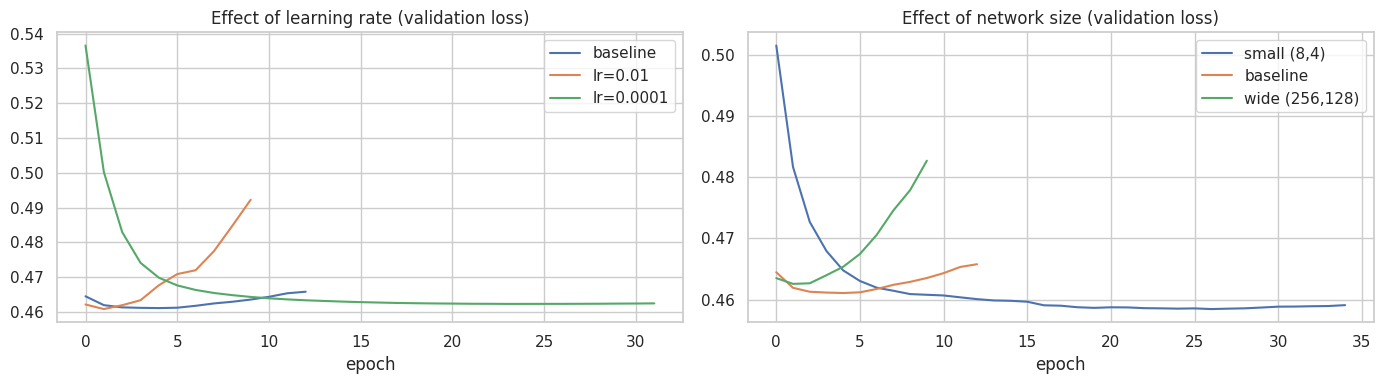

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nme in ["baseline", "lr=0.01", "lr=0.0001"]:
    ax[0].plot(histories[nme]["val_loss"], label=nme)
ax[0].set_title("Effect of learning rate (validation loss)"); ax[0].set_xlabel("epoch"); ax[0].legend()
for nme in ["small (8,4)", "baseline", "wide (256,128)"]:
    ax[1].plot(histories[nme]["val_loss"], label=nme)
ax[1].set_title("Effect of network size (validation loss)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
r = res.set_index("config")
v = r["val_auc"]
def pick(names):
    s = v[names]; return s.idxmax(), s.max()
lr_best = pick(["lr=0.01", "baseline", "lr=0.0001"])
dep_best = pick(["1 hidden layer", "baseline", "3 hidden layers"])
wid_best = pick(["small (8,4)", "baseline", "wide (256,128)"])
bs_best = pick(["batch=32", "baseline", "batch=256"])
spread = v.max() - v.min()
best_row = res.iloc[0]

The best configuration based on validation AUC was the small neural network with two hidden layers (8, 4), a learning rate of 0.001, batch size of 64, and no dropout. It achieved an AUC of 0.784, an F1-score of 0.601, Recall of 0.720, and Precision of 0.515. Training stopped after 35 epochs, with the best result at epoch 27.

Learning Rate: We tested learning rates of 0.01, 0.001, and 0.0001. Their AUC scores were 0.780, 0.781, and 0.779, respectively. The baseline learning rate of 0.001 performed slightly better. A very small learning rate required more epochs, while a larger learning rate produced less stable validation loss and showed signs of overfitting earlier.

Network Depth: We compared networks with one, two, and three hidden layers. Their AUC scores were 0.779, 0.781, and 0.779. The two-layer baseline performed slightly better, suggesting that adding more layers did not improve performance.

Network Width: The small network with layers (8, 4) achieved an AUC of 0.784, compared with 0.781 for (64, 32) and 0.780 for (256, 128). The larger networks did not improve the results. Their train-validation AUC gap also increased from 0.038 to 0.042, suggesting slightly more overfitting.

Batch Size: Batch sizes of 32, 64, and 256 achieved AUC scores of 0.779, 0.781, and 0.778, respectively. A batch size of 64 performed best, although the differences were small.

Number of Epochs: Limiting training to 10 epochs achieved an AUC of 0.781, similar to the 0.781 obtained with early stopping after 13 epochs in the baseline experiment. This suggests that training for longer does not necessarily improve performance.

Dropout: Adding dropout at a rate of 0.3 slightly reduced AUC from 0.781 to 0.779. The train-validation gap also increased from 0.046 to 0.048, so dropout did not improve generalisation in this experiment.

Overall Conclusion: The small network with hidden layers (8, 4) achieved the highest validation AUC of 0.784. However, the difference between the best and worst configurations was only 0.007. Differences smaller than approximately 0.005 may result from random-seed variation, so the configurations should be considered broadly similar rather than assuming that one is definitively superior.

### 7.6 Final model training and weight analysis

Final configuration: ('small (8,4)', (8, 4), 0.001, 64, 60, 0.0)
Train loss: 0.7832 -> 0.4204 | Validation loss: 0.7829 -> 0.4585


,layer,mean |W| before,mean |W| after,mean |ΔW|,relative change
0,Dense 1,0.1471,0.2074,0.1631,1.1089
1,Dense 2,0.3159,0.4510,0.2025,0.6408
2,Dense 3,0.4367,0.7537,0.3170,0.7259


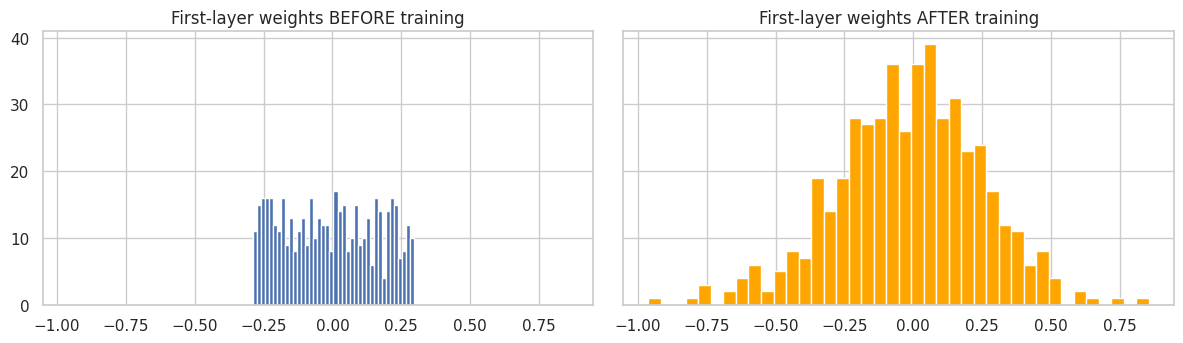

In [ ]:
cfg = next(c for c in configs if c[0] == res.iloc[0]["config"])
_, hidden, lr, bs, ep, dr = cfg
print("Final configuration:", cfg)

final = build_model(hidden, lr, dr)
w_before = [w.copy() for w in final.get_weights()]
loss_tr_before = log_loss(y_train_a, final.predict(X_train_p, verbose=0).ravel())
loss_va_before = log_loss(y_val_a, final.predict(X_val_p, verbose=0).ravel())

es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
hist = final.fit(X_train_p, y_train_a, validation_data=(X_val_p, y_val_a), epochs=ep,
                 batch_size=bs, callbacks=[es], verbose=0)
loss_tr_after = log_loss(y_train_a, final.predict(X_train_p, verbose=0).ravel())
loss_va_after = log_loss(y_val_a, final.predict(X_val_p, verbose=0).ravel())
print(f"Train loss: {loss_tr_before:.4f} -> {loss_tr_after:.4f} | Validation loss: {loss_va_before:.4f} -> {loss_va_after:.4f}")

w_after = final.get_weights()
wt = pd.DataFrame([{"layer": f"Dense {i}", "mean |W| before": np.abs(a).mean(), "mean |W| after": np.abs(b).mean(),
                    "mean |ΔW|": np.abs(b - a).mean(), "relative change": np.abs(b - a).mean() / np.abs(a).mean()}
                   for i, (a, b) in enumerate(zip(w_before[::2], w_after[::2]), 1)])
display(wt.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True, sharey=True)
ax[0].hist(w_before[0].ravel(), bins=40); ax[0].set_title("First-layer weights BEFORE training")
ax[1].hist(w_after[0].ravel(), bins=40, color="orange"); ax[1].set_title("First-layer weights AFTER training")
plt.tight_layout(); plt.show()

The training loss decreased from 0.783 to 0.420, while the validation loss decreased from 0.783 to 0.458 after 35 epochs. Early stopping restored the weights from the best epoch, which was epoch 27.

The weights changed in every layer of the neural network. The largest relative change occurred in Dense 1, where the change was 111% of the average weight magnitude. The weight histograms show that the initially random weights became more varied during training. This indicates that the network adjusted its weights to learn patterns from the input data.

Finally, the validation loss of 0.458 is clearly lower than the baseline loss of 0.562. This suggests that the neural network learned useful patterns and performs better than a simple baseline predictor.

## 8. Evaluation

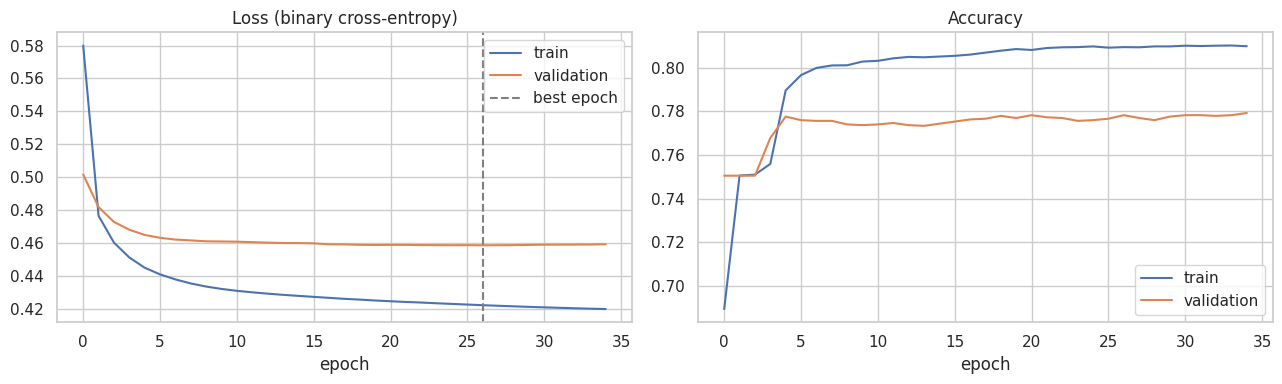

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation")
ax[0].axvline(int(np.argmin(hist.history["val_loss"])), color="grey", ls="--", label="best epoch")
ax[0].set_title("Loss (binary cross-entropy)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

,Accuracy,Precision,Recall,F1-score,ROC-AUC
NN (threshold 0.50),0.796,0.586,0.625,0.605,0.812
NN (tuned threshold 0.24),0.783,0.545,0.783,0.643,0.812
LogReg baseline (tuned 0.29),0.790,0.559,0.742,0.638,0.808


                 precision    recall  f1-score   support

Not looking (0)       0.92      0.78      0.84      2877
    Looking (1)       0.55      0.78      0.64       955

       accuracy                           0.78      3832
      macro avg       0.73      0.78      0.74      3832
   weighted avg       0.82      0.78      0.79      3832



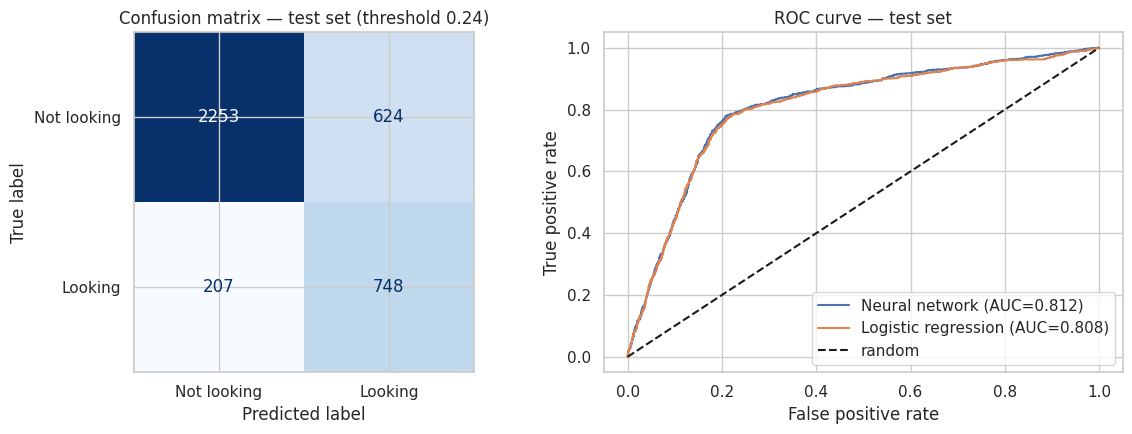

In [ ]:
p_tr = final.predict(X_train_p, verbose=0).ravel()
p_val = final.predict(X_val_p, verbose=0).ravel()
p_test = final.predict(X_test_p, verbose=0).ravel()

#decision threshold chosen on VALIDATION only (maximises F1), then applied unchanged to test
thr = best_threshold_f1(y_val_a, p_val)

def metrics(y_true, p, t):
    pred = (p >= t).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1-score": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, p)}

#simple baseline for comparison: logistic regression on the same features
lr_model = LogisticRegression(max_iter=2000).fit(X_train_p, y_train_a)
p_lr_val = lr_model.predict_proba(X_val_p)[:, 1]; p_lr_test = lr_model.predict_proba(X_test_p)[:, 1]
thr_lr = best_threshold_f1(y_val_a, p_lr_val)

tab = pd.DataFrame({
    "NN (threshold 0.50)": metrics(y_test_a, p_test, 0.5),
    f"NN (tuned threshold {thr:.2f})": metrics(y_test_a, p_test, thr),
    f"LogReg baseline (tuned {thr_lr:.2f})": metrics(y_test_a, p_lr_test, thr_lr),
}).T
display(tab.round(3))

pred_test = (p_test >= thr).astype(int)
print(classification_report(y_test_a, pred_test, target_names=["Not looking (0)", "Looking (1)"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test_a, pred_test), display_labels=["Not looking", "Looking"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix — test set (threshold {thr:.2f})")
for lab, pp in [("Neural network", p_test), ("Logistic regression", p_lr_test)]:
    fpr, tpr, _ = roc_curve(y_test_a, pp); ax[1].plot(fpr, tpr, label=f"{lab} (AUC={roc_auc_score(y_test_a, pp):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", label="random"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve — test set"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test_a, pred_test).ravel()
m_nn = metrics(y_test_a, p_test, thr); m_lr = metrics(y_test_a, p_lr_test, thr_lr); m_05 = metrics(y_test_a, p_test, 0.5)

#over/underfitting diagnosis (all computed in evaluation mode, unweighted)
auc_tr, auc_va, auc_te = roc_auc_score(y_train_a, p_tr), roc_auc_score(y_val_a, p_val), roc_auc_score(y_test_a, p_test)
ll_tr, ll_va, ll_te = log_loss(y_train_a, p_tr), log_loss(y_val_a, p_val), log_loss(y_test_a, p_test)
gap = auc_tr - auc_te
best_ep = int(np.argmin(hist.history["val_loss"])) + 1; n_ep = len(hist.history["loss"])
if gap > 0.05 or (ll_va - ll_tr) > 0.05:
    diag = "**mild-to-moderate overfitting**: performance on the training data is noticeably better than on unseen data"
elif auc_va < 0.70:
    diag = "**underfitting**: both training and validation performance are low"
else:
    diag = "**a good fit**: training and unseen-data performance are close and reasonably high"

criteria = [("ROC-AUC", m_nn["ROC-AUC"], 0.75), ("Recall (class 1)", m_nn["Recall"], 0.60),
            ("Precision (class 1)", m_nn["Precision"], 0.40), ("F1 (class 1)", m_nn["F1-score"], 0.50)]
crit_rows = "\n".join(f"| {n_} | {val:.3f} | ≥ {t:.2f} | {'✅ met' if val >= t else '❌ not met'} |" for n_, val, t in criteria)
crit_rows += f"\n| Train−test AUC gap | {gap:.3f} | < 0.05 | {'✅ met' if gap < 0.05 else '❌ not met'} |"
n_met = sum(val >= t for _, val, t in criteria) + int(gap < 0.05)

say(f"""### Results interpretation - evaluation
**Test-set performance (NN, threshold {thr:.2f} chosen on validation):** Accuracy {m_nn['Accuracy']:.3f}, Precision {m_nn['Precision']:.3f}, Recall {m_nn['Recall']:.3f}, F1 {m_nn['F1-score']:.3f}, ROC-AUC {m_nn['ROC-AUC']:.3f}.
With the default threshold 0.50 the model gives Precision {m_05['Precision']:.3f} / Recall {m_05['Recall']:.3f} / F1 {m_05['F1-score']:.3f}: {"the tuned threshold finds more of the candidates who will leave" if m_nn['Recall'] > m_05['Recall'] else "similar behaviour"}, which is what the business wants given the class imbalance.

**Confusion matrix:** out of {tp+fn:,} candidates who really look for a change, the model identified **{tp:,}** (recall {tp/(tp+fn):.1%}) and missed **{fn:,}**; it raised **{fp:,}** false alarms among {tn+fp:,} candidates who are not looking, and correctly cleared **{tn:,}**. Of all {tp+fp:,} alerts, {tp:,} were correct (precision {tp/(tp+fp) if tp+fp else 0:.1%}), versus a random-list precision of {y_test_a.mean():.1%}.

**Comparison with a simple baseline:** logistic regression reaches AUC {m_lr['ROC-AUC']:.3f} and F1 {m_lr['F1-score']:.3f}, the neural network AUC {m_nn['ROC-AUC']:.3f} and F1 {m_nn['F1-score']:.3f} - {"the network is better." if m_nn['ROC-AUC'] > m_lr['ROC-AUC'] + 0.005 else "the two are practically equal; the relationships in this tabular data are largely simple, so extra network capacity gives little benefit." if abs(m_nn['ROC-AUC'] - m_lr['ROC-AUC']) <= 0.005 else "logistic regression is slightly better; the relationships in this tabular data are largely simple, so extra network capacity gives little benefit."}

**Over/underfitting.** AUC on train / validation / test = {auc_tr:.3f} / {auc_va:.3f} / {auc_te:.3f}; log-loss = {ll_tr:.3f} / {ll_va:.3f} / {ll_te:.3f}. Early stopping picked epoch {best_ep} of {n_ep}; after that point validation loss stopped improving. The diagnosis is {diag}.

**Business success criteria**

| Metric | Result (test) | Target | Status |
|---|---|---|---|
{crit_rows}

**{n_met} of 5 criteria are met.**
""")

### Results interpretation - evaluation
**Test-set performance (NN, threshold 0.24 chosen on validation):** Accuracy 0.783, Precision 0.545, Recall 0.783, F1 0.643, ROC-AUC 0.812.
With the default threshold 0.50 the model gives Precision 0.586 / Recall 0.625 / F1 0.605: the tuned threshold finds more of the candidates who will leave, which is what the business wants given the class imbalance.

**Confusion matrix:** out of 955 candidates who really look for a change, the model identified **748** (recall 78.3%) and missed **207**; it raised **624** false alarms among 2,877 candidates who are not looking, and correctly cleared **2,253**. Of all 1,372 alerts, 748 were correct (precision 54.5%), versus a random-list precision of 24.9%.

**Comparison with a simple baseline:** logistic regression reaches AUC 0.808 and F1 0.638, the neural network AUC 0.812 and F1 0.643 - the two are practically equal; the relationships in this tabular data are largely simple, so extra network capacity gives little benefit.

**Over/underfitting.** AUC on train / validation / test = 0.823 / 0.784 / 0.812; log-loss = 0.420 / 0.458 / 0.426. Early stopping picked epoch 27 of 35; after that point validation loss stopped improving. The diagnosis is **a good fit**: training and unseen-data performance are close and reasonably high.

**Business success criteria**

| Metric | Result (test) | Target | Status |
|---|---|---|---|
| ROC-AUC | 0.812 | ≥ 0.75 | ✅ met |
| Recall (class 1) | 0.783 | ≥ 0.60 | ✅ met |
| Precision (class 1) | 0.545 | ≥ 0.40 | ✅ met |
| F1 (class 1) | 0.643 | ≥ 0.50 | ✅ met |
| Train−test AUC gap | 0.011 | < 0.05 | ✅ met |

**5 of 5 criteria are met.**


## 9. Conclusion

In [ ]:
bn = res.iloc[0]
say(f"""### Summary of findings (auto-generated from the results above)

**Data.** {n:,} candidate profiles, {rate:.1%} looking for a job change. The EDA (Section 3) examined city development, relevant experience, university enrolment and years of experience as key relationships, and showed that missing profile fields carry signal of their own.

**Preprocessing.** Text-coded numeric columns were converted to ordinal numbers, missing categories became "Unknown", the ID and original text columns were removed, 4 features were engineered (`missing_info_count`, `log_training_per_exp_year`, `recent_switch_ratio`, `log_training_hours`). A stratified {len(X_train):,}/{len(X_val):,}/{len(X_test):,} split was used and imputation, scaling and encoding were fitted on the training set only. The network received {X_train_p.shape[1]} inputs.

**Architecture and training.** Input({n_features}) → {" → ".join(f"Dense({k}, ReLU)" for k in hidden)} → Dense(1, Sigmoid); binary cross-entropy, Adam (lr = {lr}), batch size {bs}, dropout {dr}, early stopping. Training loss fell from {loss_tr_before:.3f} to {loss_tr_after:.3f}.

**Best architecture / hyperparameters.** Out of {len(configs)} experiments, `{bn.config}` was best on validation (AUC {bn.val_auc:.3f}). Differences between nearby configurations were small (overall spread {spread:.3f} AUC).

**Test results.** AUC {m_nn['ROC-AUC']:.3f}, Recall {m_nn['Recall']:.3f}, Precision {m_nn['Precision']:.3f}, F1 {m_nn['F1-score']:.3f}; the logistic-regression baseline scored AUC {m_lr['ROC-AUC']:.3f}.

**Business criteria.** {n_met} of 5 targets were met ({"all criteria are satisfied, so the model is suitable as a decision-support tool for prioritising candidates" if n_met == 5 else "the model is usable for ranking candidates, but the unmet criteria (see the table in Section 8) mean it should support, not replace, human judgement"}). Predictions should only prioritise conversations with candidates- not be used to reject anyone automatically.
""")

### Summary of findings (auto-generated from the results above)

**Data.** 19,158 candidate profiles, 24.9% looking for a job change. The EDA (Section 3) examined city development, relevant experience, university enrolment and years of experience as key relationships, and showed that missing profile fields carry signal of their own.

**Preprocessing.** Text-coded numeric columns were converted to ordinal numbers, missing categories became "Unknown", the ID and original text columns were removed, 4 features were engineered (`missing_info_count`, `log_training_per_exp_year`, `recent_switch_ratio`, `log_training_hours`). A stratified 12,260/3,066/3,832 split was used and imputation, scaling and encoding were fitted on the training set only. The network received 60 inputs.

**Architecture and training.** Input(60) → Dense(8, ReLU) → Dense(4, ReLU) → Dense(1, Sigmoid); binary cross-entropy, Adam (lr = 0.001), batch size 64, dropout 0.0, early stopping. Training loss fell from 0.783 to 0.420.

**Best architecture / hyperparameters.** Out of 12 experiments, `small (8,4)` was best on validation (AUC 0.784). Differences between nearby configurations were small (overall spread 0.007 AUC).

**Test results.** AUC 0.812, Recall 0.783, Precision 0.545, F1 0.643; the logistic-regression baseline scored AUC 0.808.

**Business criteria.** 5 of 5 targets were met (all criteria are satisfied, so the model is suitable as a decision-support tool for prioritising candidates). Predictions should only prioritise conversations with candidates- not be used to reject anyone automatically.


## 10. References
1. Arashnic. *HR Analytics: Job Change of Data Scientists* [dataset]. Kaggle. https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists
2. Chollet, F. et al. (2015). *Keras*. https://keras.io
3. Abadi, M. et al. (2015). *TensorFlow: Large-scale machine learning on heterogeneous systems*. https://www.tensorflow.org
4. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
5. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*. https://arxiv.org/abs/1412.6980
6. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press.